## 1. Chargement des données

Les données viennent de Hugging Face, en deux fichiers `.parquet` : train et test. Ce découpage est aléatoire et ne nous sert pas, alors on recolle tout. On refera notre propre découpage dans le temps plus tard.

In [1]:
import pandas as pd

train = pd.read_parquet("../data/train.parquet")
test = pd.read_parquet("../data/test.parquet")

df = pd.concat([train, test], ignore_index=True)
print(train.shape, test.shape, df.shape)
df.head()

(91529, 18) (22883, 18) (114412, 18)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,esa_source,esa_processed
0,2020-08-15,Alibori,Karimama,Karimama,2771,12.07,3.18,cereals and tubers,Millet,73,KG,actual,Retail,XOF,200.00,0.36,HDX,2026-04-06
1,2025-07-15,Oueme,Adjohoun,Azowlissè,2554,6.67,2.49,oil and fats,Oil (palm),62,L,actual,Retail,XOF,837.50,1.49,HDX,2026-04-06
2,2021-07-15,Borgou,Sinende,Sinendé,1750,10.34,2.38,cereals and tubers,Rice (imported),64,KG,actual,Retail,XOF,478.72,0.87,HDX,2026-04-06
3,2025-05-15,Atlantique,Allada,Sékou,2777,6.63,2.22,pulses and nuts,"Groundnuts (small, unshelled)",557,KG,actual,Retail,XOF,1216.25,2.11,HDX,2026-04-06
4,2023-03-15,Zou,Cove,Covè,2765,7.22,2.34,cereals and tubers,Sorghum (red),282,KG,actual,Retail,XOF,344.83,0.57,HDX,2026-04-06


## 2. Aperçu des colonnes

On regarde le type de chaque colonne et s'il y a des valeurs manquantes.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114412 entries, 0 to 114411
Data columns (total 18 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   date           114412 non-null  datetime64[ns]
 1   admin1         114412 non-null  object        
 2   admin2         114412 non-null  object        
 3   market         114412 non-null  object        
 4   market_id      114412 non-null  int64         
 5   latitude       114412 non-null  float64       
 6   longitude      114412 non-null  float64       
 7   category       114412 non-null  object        
 8   commodity      114412 non-null  object        
 9   commodity_id   114412 non-null  int64         
 10  unit           114412 non-null  object        
 11  priceflag      114412 non-null  object        
 12  pricetype      114412 non-null  object        
 13  currency       114412 non-null  object        
 14  price          114412 non-null  float64       
 15  

## 3. Nombre de valeurs différentes par colonne

Ça permet de repérer les colonnes qui ne servent à rien (une seule valeur partout) et de voir combien on a de marchés, de produits, etc.

In [3]:
df.nunique()

date               254
admin1              12
admin2              46
market              51
market_id           51
latitude            48
longitude           42
category             6
commodity           53
commodity_id        53
unit                 2
priceflag            1
pricetype            2
currency             1
price            13978
usdprice          1659
esa_source           1
esa_processed        1
dtype: int64

## 4. Les types de prix

La colonne `pricetype` a deux valeurs. On regarde lesquelles et combien de lignes on a pour chacune.

In [4]:
df["pricetype"].value_counts()

pricetype
Retail       114196
Wholesale       216
Name: count, dtype: int64

## 5. Que contiennent les prix de gros ?

Avant de supprimer les 216 lignes Wholesale, on regarde quels produits et quels marchés elles concernent, et si ces produits ont aussi des prix de détail ailleurs.

In [5]:
gros = df[df["pricetype"] == "Wholesale"]
print(gros.groupby(["commodity", "market"]).size())

detail = df[df["pricetype"] == "Retail"]
print(gros["commodity"].unique())
print(gros["commodity"].isin(detail["commodity"]).all())

commodity        market          
Maize            Malanville (CBM)    48
Millet           Malanville (CBM)    73
Rice (imported)  Malanville (CBM)    72
Sorghum          Malanville (CBM)    13
Wheat            Malanville (CBM)    10
dtype: int64
['Rice (imported)' 'Sorghum' 'Millet' 'Maize' 'Wheat']
True


## 6. Premier nettoyage

Les prix de gros viennent tous d'un seul marché (Malanville) et concernent des produits qu'on a aussi en prix de détail, donc on ne garde que le détail. On enlève aussi les colonnes qui ont la même valeur partout.

In [6]:
df = df[df["pricetype"] == "Retail"]
df = df.drop(columns=["pricetype", "priceflag", "currency", "esa_source", "esa_processed"])
df.shape

(114196, 13)

## 7. Doublons

On cherche d'abord les lignes identiques, puis les cas où on a plusieurs prix pour le même produit, sur le même marché, le même mois.

In [7]:
print(df.duplicated().sum())

cle = ["date", "market", "commodity", "unit"]
print(df.duplicated(subset=cle).sum())

0
0


## 8. Les produits et leurs périodes

Certains produits ont plusieurs noms (Maize, Maize (white)…). On regarde pour chaque nom combien de relevés on a et sur quelle période, pour voir si un nom en a remplacé un autre.

In [8]:
produits = df.groupby("commodity")["date"].agg(["count", "min", "max"])
produits.sort_index()

,count,min,max
commodity,,,
Beans (black),765,2020-04-15,2026-02-15
Beans (red),2684,2019-01-15,2026-02-15
Beans (white),3617,2007-01-15,2026-02-15
Cabbage,1505,2020-04-15,2026-02-15
Carrots,1986,2019-01-15,2026-02-15
Cassava (cossette),1241,2020-04-15,2026-02-15
Cassava (fresh),1028,2020-04-15,2026-02-15
Cassava flour,1201,2020-04-15,2026-02-15
Cassava meal (gari),4096,2007-02-15,2026-02-15


## 9. Nombre de relevés par année

Beaucoup de produits n'apparaissent qu'à partir de 2019-2020. On regarde combien de relevés on a chaque année pour voir à partir de quand les données deviennent vraiment denses.

In [9]:
df.groupby(df["date"].dt.year).agg(releves=("price", "size"), marches=("market", "nunique"), produits=("commodity", "nunique"))

,releves,marches,produits
date,,,
2007,51,1,5
2008,47,1,5
2009,44,1,5
2010,49,1,5
2011,46,1,5
2012,86,2,5
2013,122,4,7
2014,370,21,7
2015,977,21,7


## 10. On garde les données à partir de 2019

Avant 2019, on n'a souvent qu'un seul marché. À partir de 2019, on a une cinquantaine de marchés et de produits chaque année, c'est là que les données sont vraiment utilisables. On garde quand même une copie complète au cas où on veut regarder le long terme.

In [10]:
df_complet = df.copy()
df = df[df["date"] >= "2019-01-01"]
df.shape

(111432, 13)

## 11. Combien de mois par série ?

Une série, c'est un produit sur un marché (par exemple le maïs blanc à Dantokpa). Depuis janvier 2019, il y a 86 mois possibles. On compte combien de mois chaque série a réellement.

In [11]:
series = df.groupby(["commodity", "market"])["date"].agg(["count", "min", "max"])
print(len(series))
series["count"].describe()

2312


count    2312.000000
mean       48.197232
std        25.202804
min         1.000000
25%        29.000000
50%        58.000000
75%        69.000000
max        85.000000
Name: count, dtype: float64

## 12. Quelles séries garder ?

On garde les séries qui ont au moins 48 mois (4 ans) et qui vont au moins jusqu'en 2025, pour avoir assez d'historique et pouvoir les tester sur la fin de la période. On regarde combien il en reste.

In [12]:
bonnes = series[(series["count"] >= 48) & (series["max"] >= "2025-01-01")]
print(len(bonnes))
print(bonnes.index.get_level_values("commodity").nunique(), "produits")
print(bonnes.index.get_level_values("market").nunique(), "marchés")

1390
49 produits
50 marchés


## 13. Sur combien de marchés chaque produit est bien suivi ?

On compte, pour chaque produit, le nombre de marchés où sa série est assez longue. Ça nous aidera à choisir les produits qu'on mettra en avant.

In [13]:
bonnes.groupby("commodity").size().sort_values(ascending=False)

commodity
Sorghum (red)                    49
Cassava meal (gari)              49
Oil (groundnut)                  48
Onions                           47
Cassava meal (tapioca)           47
Tomatoes                         47
Groundnuts (Bambara)             45
Peppers (red, dry)               44
Rice (imported)                  44
Groundnuts (small, unshelled)    44
Oranges                          43
Okra (fresh)                     43
Fish (fresh, silvi)              42
Soybeans                         42
Wheat flour (imported)           41
Maize (white)                    40
Beans (white)                    39
Lemons                           38
Cassava meal (gari, fine)        37
Oil (palm)                       37
Beans (red)                      35
Millet                           35
Leafy vegetables                 34
Coconut (dried)                  33
Yam (white)                      30
Yam                              27
Rice (local)                     25
Sorghum           

## 14. Les produits phares

Pour l'analyse et la démo, on se concentre sur 6 produits : gari, riz importé, maïs blanc, haricot blanc, tomate et huile d'arachide. Ce sont des produits de base, suivis sur beaucoup de marchés. On regarde d'abord leurs prix en chiffres (attention, l'huile est au litre).

In [14]:
phares = ["Cassava meal (gari)", "Rice (imported)", "Maize (white)", "Beans (white)", "Tomatoes", "Oil (groundnut)"]
df_phares = df[df["commodity"].isin(phares)]

df_phares.groupby(["commodity", "unit"])["price"].describe().round(0)

,,count,mean,std,min,25%,50%,75%,max
commodity,unit,,,,,,,,
Beans (white),KG,3120.0,610.0,169.0,170.0,489.0,598.0,693.0,1461.0
Cassava meal (gari),KG,3477.0,359.0,118.0,88.0,286.0,357.0,429.0,1106.0
Maize (white),KG,2931.0,211.0,60.0,26.0,169.0,205.0,247.0,576.0
Oil (groundnut),L,3397.0,1152.0,251.0,550.0,1000.0,1150.0,1308.0,1960.0
Rice (imported),KG,3212.0,545.0,101.0,215.0,479.0,532.0,604.0,1223.0
Tomatoes,KG,3332.0,469.0,312.0,52.0,287.0,417.0,575.0,4075.0


## 15. Les prix bizarres

Certains prix sont très loin de la médiane de leur produit (tomate à 4 075 FCFA/kg, maïs à 26 FCFA/kg). On affiche les prix plus de 3 fois au-dessus ou en dessous de la médiane de leur produit, pour voir si ce sont des erreurs ou de vrais pics.

In [15]:
mediane = df_phares.groupby("commodity")["price"].transform("median")
ratio = df_phares["price"] / mediane

bizarres = df_phares[(ratio > 3) | (ratio < 1/3)]
print(len(bizarres))
bizarres[["date", "market", "commodity", "price"]].sort_values(["commodity", "date"])


187


,date,market,commodity,price
11419,2019-08-15,Cobly,Beans (white),187.07
9658,2019-10-15,Cobly,Beans (white),170.07
10595,2022-12-15,Tchaourou,Beans (white),192.93
47016,2019-01-15,Kétou,Cassava meal (gari),105.09
56284,2019-01-15,Ouesse,Cassava meal (gari),110.29
...,...,...,...,...
113104,2025-10-15,Tatonnoukon,Tomatoes,3837.50
2585,2025-11-15,Tatonnoukon,Tomatoes,2237.50
58673,2025-12-15,Tatonnoukon,Tomatoes,4075.00
86716,2026-02-15,Tatonnoukon,Tomatoes,4041.67


## 16. Où sont les prix bizarres ?

On compte les prix bizarres par produit et par marché. Si un même marché revient beaucoup, le problème vient sûrement de ce marché (une unité différente, par exemple). Sinon, ce sont plutôt des valeurs isolées.

In [16]:
bizarres.groupby(["commodity", "market"]).size().sort_values(ascending=False).head(15)

commodity            market     
Tomatoes             Tatonnoukon    18
                     Covè           12
Cassava meal (gari)  Azovè           9
Tomatoes             Dogbo           9
Cassava meal (gari)  Kétou           8
                     Ouesse          8
Tomatoes             Zinvié          7
                     Kétou           7
                     Dassa-Zoumè     6
                     Azowlissè       6
                     Kpedekpo        6
                     Comé            5
                     Klouékanmè      5
                     Zè              5
                     Azovè           5
dtype: int64

## 17. La tomate à Tatonnoukon et Covè

La plupart des prix bizarres concernent la tomate, sur plein de marchés : c'est surtout un produit très instable. Mais Tatonnoukon et Covè reviennent souvent. On compare leurs prix à la médiane nationale pour voir s'ils suivent les mêmes mouvements.

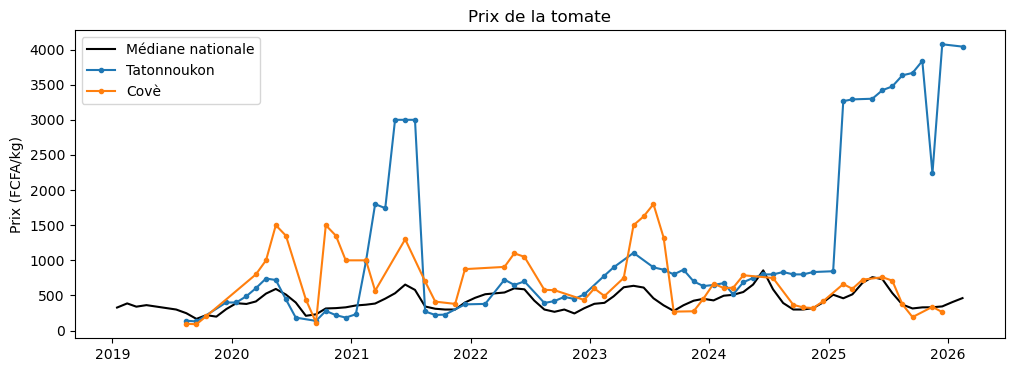

In [17]:
import matplotlib.pyplot as plt

tomate = df_phares[df_phares["commodity"] == "Tomatoes"]
mediane_nat = tomate.groupby("date")["price"].median()

plt.figure(figsize=(12, 4))
plt.plot(mediane_nat, label="Médiane nationale", color="black")
for m in ["Tatonnoukon", "Covè"]:
    serie = tomate[tomate["market"] == m].set_index("date")["price"].sort_index()
    plt.plot(serie, label=m, marker=".")
plt.ylabel("Prix (FCFA/kg)")
plt.title("Prix de la tomate")
plt.legend()
plt.show()

## 18. On retire la tomate de Tatonnoukon

Covè a des pics plus forts que la moyenne, mais qui tombent aux mêmes moments que le reste du pays : ce sont de vrais prix. À Tatonnoukon, par contre, le prix reste bloqué vers 3 000 FCFA/kg en 2021, puis saute à plus de 3 300 FCFA/kg à partir de 2025, alors que le reste du pays ne bouge pas. Ça ressemble à une erreur ou à un changement d'unité, donc on retire cette série.

In [18]:
retrait = (df["commodity"] == "Tomatoes") & (df["market"] == "Tatonnoukon")
print(retrait.sum())

df = df[~retrait]
df_phares = df[df["commodity"].isin(phares)]
df.shape

66


(111366, 13)

## 19. Le gari à Azovè, Ouesse et Kétou

Le gari a aussi quelques prix bizarres sur ces trois marchés. On les compare à la médiane nationale, comme pour la tomate.

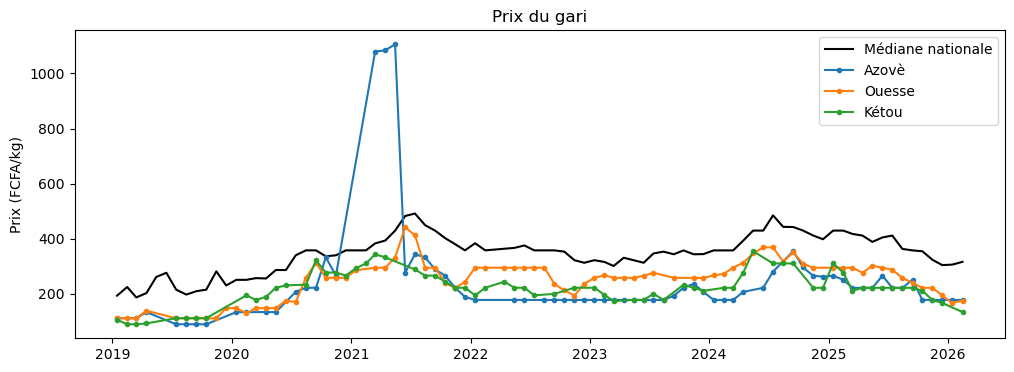

In [19]:
gari = df_phares[df_phares["commodity"] == "Cassava meal (gari)"]
mediane_nat = gari.groupby("date")["price"].median()

plt.figure(figsize=(12, 4))
plt.plot(mediane_nat, label="Médiane nationale", color="black")
for m in ["Azovè", "Ouesse", "Kétou"]:
    serie = gari[gari["market"] == m].set_index("date")["price"].sort_index()
    plt.plot(serie, label=m, marker=".")
plt.ylabel("Prix (FCFA/kg)")
plt.title("Prix du gari")
plt.legend()
plt.show()

## 20. On corrige le pic du gari à Azovè

Les trois marchés sont un peu moins chers que la moyenne du pays, mais ils suivent les mêmes mouvements : ce sont de vrais prix. Seul Azovè a un pic à plus de 1 000 FCFA/kg début 2021 que personne d'autre n'a. On supprime juste ces mois-là et on garde le reste de la série.

In [20]:
erreur = (df["commodity"] == "Cassava meal (gari)") & (df["market"] == "Azovè") & (df["price"] > 1000)
print(df[erreur][["date", "price"]])

df = df[~erreur]
df_phares = df[df["commodity"].isin(phares)]
df.shape

             date    price
1577   2021-03-15  1079.65
94202  2021-04-15  1084.07
103242 2021-05-15  1106.19


(111363, 13)

## 21. On garde les produits phares et les bonnes séries

Pour la suite, on se limite aux 6 produits phares, et seulement aux séries assez longues (au moins 48 mois et qui vont jusqu'en 2025).

In [21]:
bonnes_phares = bonnes[bonnes.index.get_level_values("commodity").isin(phares)].index

df = df.set_index(["commodity", "market"])
df = df[df.index.isin(bonnes_phares)].reset_index()

print(df.shape)
print(df.groupby("commodity")["market"].nunique())

(18201, 13)
commodity
Beans (white)          39
Cassava meal (gari)    49
Maize (white)          40
Oil (groundnut)        48
Rice (imported)        44
Tomatoes               46
Name: market, dtype: int64


## 22. Recherche automatique des prix bizarres

On compare chaque prix à la médiane du même produit, le même mois, dans tout le pays. Comme ça, une hausse de saison n'est pas prise pour une erreur, puisque tous les marchés montent ensemble. Un prix plus de 3 fois au-dessus ou en dessous de cette médiane est suspect.

In [22]:
med_mois = df.groupby(["commodity", "date"])["price"].transform("median")
df["ratio"] = df["price"] / med_mois

suspects = df[(df["ratio"] > 3) | (df["ratio"] < 1/3)]
print(len(suspects))
suspects[["date", "market", "commodity", "price", "ratio"]].sort_values(["commodity", "market", "date"])

59


,date,market,commodity,price,ratio
8142,2021-09-15,Banikoara,Beans (white),234.08,0.330626
4749,2020-03-15,Dangbo,Maize (white),575.76,3.646589
4648,2021-10-15,Azovè,Tomatoes,52.50,0.175000
1492,2021-11-15,Azovè,Tomatoes,85.00,0.283333
3855,2022-11-15,Azovè,Tomatoes,78.75,0.330424
7091,2023-04-15,Bassila,Tomatoes,190.00,0.308004
13006,2023-05-15,Bassila,Tomatoes,190.00,0.298039
13852,2024-05-15,Bassila,Tomatoes,200.00,0.294118
214,2024-06-15,Bassila,Tomatoes,200.00,0.227402
2555,2021-05-15,Cobly,Tomatoes,121.50,0.229245
